In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:

import os
import glob
import time
import copy
import random
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image, ImageFile
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr

In [4]:
# ---------------- CONFIGURATION ----------------
SEED = 42
IMG_SIZE = 128
BATCH_SIZE = 16
EPOCHS = 100
LR = 1e-3
PATIENCE = 12
BASE_CHANNELS = 32

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ── Auto-detect Google Colab vs local ───────────────────────────────────────
import sys, os
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules or 'COLAB_GPU' in os.environ

if IN_COLAB:
    # ---------- COLAB SETUP ----------
    BASE = '/content/drive/MyDrive/ConstructionSiteAi'
    DATA = os.path.join(BASE, 'ConstructionSiteSafetyImageDatasetRoboflow', 'css-data')
    OUT = os.path.join(BASE, 'data', 'processed', 'features', 'ae_v2')
else:
    # ---------- LOCAL SETUP ----------
    possible_data = [
        r'C:\Users\mrpat\Downloads\Constructio_Site_AI\ConstructionSiteSafetyImageDatasetRoboflow\css-data',
        r'C:\Desktop\ConstructionAI\Constructionsite_ai\data',
        os.path.abspath(os.path.join(os.getcwd(), '..', 'data')),
    ]
    DATA = next((p for p in possible_data if os.path.exists(p)), possible_data[0])
    possible_out = [
        r'C:\Desktop\ConstructionAI\Constructionsite_ai\weights',
        os.path.abspath(os.path.join(os.getcwd(), '..', 'weights')),
    ]
    OUT = next((p for p in possible_out if os.path.exists(p)), possible_out[0])

os.makedirs(OUT, exist_ok=True)
print('Environment:', 'Google Colab' if IN_COLAB else 'Local Workstation')
print('Dataset    :', DATA)
print('Output     :', OUT)


Dataset   : /content/drive/MyDrive/ConstructionSiteAi/ConstructionSiteSafetyImageDatasetRoboflow/css-data
Output    : /content/drive/MyDrive/ConstructionSiteAi/data/processed/features/ae_v2


In [5]:
# ---------------- DATASET ----------------
class ConstructionImageDataset(Dataset):
    def __init__(self, img_dir):
        # Support both lowercase and uppercase extensions
        extensions = ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.webp", "*.JPG", "*.JPEG", "*.PNG", "*.BMP", "*.WEBP")
        self.img_paths = []
        for ext in extensions:
            self.img_paths.extend(glob.glob(os.path.join(img_dir, ext)))
        self.img_paths = sorted(self.img_paths)

        self.transform = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
        ])

        if not self.img_paths:
            # Diagnostics to help identify path issues
            parent_dir = os.path.dirname(img_dir) if os.path.exists(os.path.dirname(img_dir)) else "None"
            contents = os.listdir(parent_dir) if parent_dir != "None" else []
            raise RuntimeError(
                f"No images found in: {img_dir}\n"
                f"Parent directory exists: {os.path.exists(parent_dir)}\n"
                f"Contents of parent directory ({parent_dir}): {contents}"
            )

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        path = self.img_paths[idx]
        try:
            with Image.open(path) as image:
                image = image.convert("RGB")
                return self.transform(image)
        except Exception as exc:
            raise RuntimeError(f"Failed to load {path}") from exc

try:
    train_ds = ConstructionImageDataset(os.path.join(DATA, "train", "images"))
    val_ds = ConstructionImageDataset(os.path.join(DATA, "valid", "images"))
    test_ds = ConstructionImageDataset(os.path.join(DATA, "test", "images"))
except RuntimeError as e:
    print("Error initializing datasets:")
    print(e)
    train_ds, val_ds, test_ds = None, None, None

if train_ds is not None if 'train_ds' in locals() and train_ds is not None else False:
    # num_workers=0 is a safe starting point on Windows.
    # Pin memory only when using CUDA.
    loader_args = {
        "batch_size": BATCH_SIZE,
        "num_workers": 0,
        "pin_memory": DEVICE.type == "cuda",
    }

    train_loader = DataLoader(train_ds, shuffle=True, **loader_args)
    val_loader = DataLoader(val_ds, shuffle=False, **loader_args)
    test_loader = DataLoader(test_ds, shuffle=False, **loader_args)

    print(f"Train: {len(train_ds)} | Valid: {len(val_ds)} | Test: {len(test_ds)}")
else:
    print("\nPlease check the diagnostic output above to locate your dataset images in Google Drive.")

Train: 2605 | Valid: 114 | Test: 82


In [6]:
# ---------------- MODEL ----------------
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.LeakyReLU(0.1, inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.LeakyReLU(0.1, inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class AutoencoderV2(nn.Module):
    def __init__(self, base=32):
        super().__init__()

        # Encoder: 128 -> 64 -> 32 -> 16 -> 8
        self.enc1 = ConvBlock(3, base)
        self.enc2 = ConvBlock(base, base * 2)
        self.enc3 = ConvBlock(base * 2, base * 4)
        self.enc4 = ConvBlock(base * 4, base * 4)

        self.pool = nn.MaxPool2d(2)

        # Spatial bottleneck: 128 x 8 x 8
        self.bottleneck = ConvBlock(base * 4, base * 4)

        # Decoder with spatial skip connections
        self.up4 = nn.ConvTranspose2d(base * 4, base * 4, 2, 2)
        self.dec4 = ConvBlock(base * 8, base * 4)

        self.up3 = nn.ConvTranspose2d(base * 4, base * 4, 2, 2)
        self.dec3 = ConvBlock(base * 8, base * 2)

        self.up2 = nn.ConvTranspose2d(base * 2, base * 2, 2, 2)
        self.dec2 = ConvBlock(base * 4, base)

        self.up1 = nn.ConvTranspose2d(base, base, 2, 2)
        self.dec1 = ConvBlock(base * 2, base)

        self.output = nn.Sequential(
            nn.Conv2d(base, 3, kernel_size=1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        e1 = self.enc1(x)               # 128 x 128
        e2 = self.enc2(self.pool(e1))   # 64 x 64
        e3 = self.enc3(self.pool(e2))   # 32 x 32
        e4 = self.enc4(self.pool(e3))   # 16 x 16

        z = self.bottleneck(self.pool(e4))  # 8 x 8

        d4 = self.up4(z)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output(d1), z


model = AutoencoderV2(BASE_CHANNELS).to(DEVICE)
criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LR, weight_decay=1e-5
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=4
)

print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

Parameters: 1,731,747


In [7]:
# ---------------- TRAINING ----------------
history = {"train_loss": [], "val_loss": []}
best_val = float("inf")
best_epoch = 0
best_state = None
wait = 0

best_path = os.path.join(OUT, "autoencoder_v2_best.pth")

for epoch in range(1, EPOCHS + 1):
    start = time.time()

    model.train()
    train_sum = 0.0

    for batch in train_loader:
        batch = batch.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        recon, _ = model(batch)
        loss = criterion(recon, batch)
        loss.backward()
        optimizer.step()

        train_sum += loss.item() * batch.size(0)

    train_loss = train_sum / len(train_ds)

    model.eval()
    val_sum = 0.0

    with torch.inference_mode():
        for batch in val_loader:
            batch = batch.to(DEVICE, non_blocking=True)
            recon, _ = model(batch)
            val_sum += criterion(recon, batch).item() * batch.size(0)

    val_loss = val_sum / len(val_ds)
    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if val_loss < best_val:
        best_val = val_loss
        best_epoch = epoch
        wait = 0

        # Copy to CPU so the checkpoint is independent of later updates.
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }

        torch.save({
            "epoch": best_epoch,
            "model_state_dict": best_state,
            "val_loss": best_val,
            "config": {
                "img_size": IMG_SIZE,
                "base_channels": BASE_CHANNELS,
                "architecture": "AutoencoderV2",
            },
        }, best_path)
    else:
        wait += 1

    elapsed = time.time() - start
    print(
        f"Epoch {epoch:03d}/{EPOCHS} | "
        f"train={train_loss:.6f} | val={val_loss:.6f} | "
        f"lr={optimizer.param_groups[0]['lr']:.2e} | "
        f"{elapsed:.1f}s"
    )

    if wait >= PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

# Restore best validation checkpoint
model.load_state_dict(best_state)
model.eval()

print(f"Best epoch: {best_epoch}, validation MSE: {best_val:.6f}")

Epoch 001/100 | train=0.007476 | val=0.001592 | lr=1.00e-03 | 104.5s
Epoch 002/100 | train=0.002828 | val=0.001999 | lr=1.00e-03 | 35.2s
Epoch 003/100 | train=0.002403 | val=0.000974 | lr=1.00e-03 | 36.2s
Epoch 004/100 | train=0.001844 | val=0.003248 | lr=1.00e-03 | 34.4s
Epoch 005/100 | train=0.002049 | val=0.002031 | lr=1.00e-03 | 34.6s
Epoch 006/100 | train=0.001487 | val=0.001059 | lr=1.00e-03 | 34.5s
Epoch 007/100 | train=0.001698 | val=0.000436 | lr=1.00e-03 | 34.1s
Epoch 008/100 | train=0.001393 | val=0.000574 | lr=1.00e-03 | 33.8s
Epoch 009/100 | train=0.001603 | val=0.000814 | lr=1.00e-03 | 34.1s
Epoch 010/100 | train=0.001089 | val=0.000570 | lr=1.00e-03 | 34.1s
Epoch 011/100 | train=0.001005 | val=0.000393 | lr=1.00e-03 | 34.6s
Epoch 012/100 | train=0.000986 | val=0.000520 | lr=1.00e-03 | 35.1s
Epoch 013/100 | train=0.001159 | val=0.002210 | lr=1.00e-03 | 34.6s
Epoch 014/100 | train=0.001151 | val=0.000692 | lr=1.00e-03 | 34.8s
Epoch 015/100 | train=0.000746 | val=0.000251 |

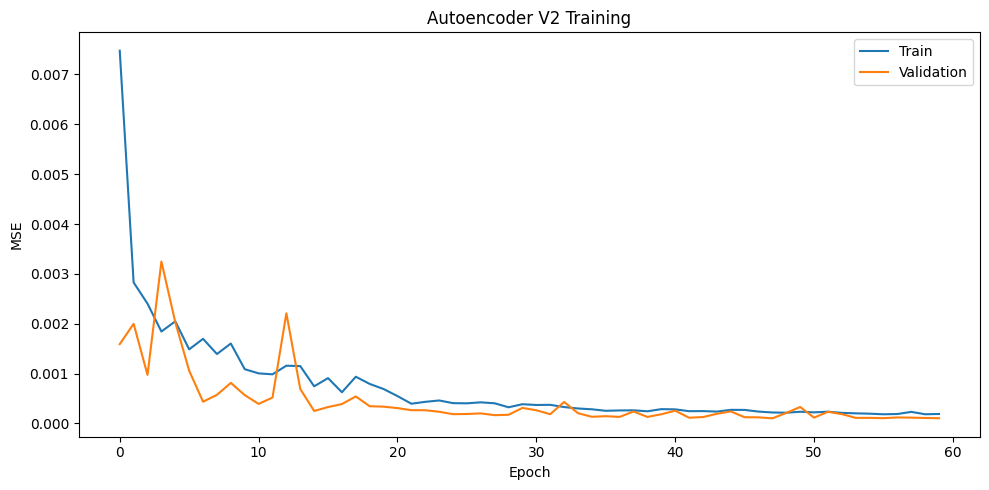

In [8]:
# ---------------- LOSS CURVE ----------------
plt.figure(figsize=(10, 5))
plt.plot(history["train_loss"], label="Train")
plt.plot(history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Autoencoder V2 Training")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT, "ae_v2_loss.png"), dpi=150)
plt.show()


In [9]:
# ---------------- TEST METRICS ----------------
mse_scores, ssim_scores, psnr_scores = [], [], []
originals, reconstructions = [], []

with torch.inference_mode():
    for batch in test_loader:
        batch = batch.to(DEVICE, non_blocking=True)
        recon, _ = model(batch)

        originals.append(batch.cpu())
        reconstructions.append(recon.cpu())

        orig_np = batch.cpu().permute(0, 2, 3, 1).numpy()
        rec_np = recon.cpu().permute(0, 2, 3, 1).numpy()

        for orig, rec in zip(orig_np, rec_np):
            mse_scores.append(float(np.mean((orig - rec) ** 2)))
            ssim_scores.append(float(ssim(
                orig, rec, channel_axis=2, data_range=1.0
            )))
            psnr_scores.append(float(psnr(
                orig, rec, data_range=1.0
            )))

print("\nTEST RESULTS")
print(f"MSE : {np.mean(mse_scores):.6f} +/- {np.std(mse_scores):.6f}")
print(f"SSIM: {np.mean(ssim_scores):.4f} +/- {np.std(ssim_scores):.4f}")
print(f"PSNR: {np.mean(psnr_scores):.2f} +/- {np.std(psnr_scores):.2f} dB")

# Save machine-readable metrics
np.savez(
    os.path.join(OUT, "ae_v2_metrics.npz"),
    mse=np.asarray(mse_scores),
    ssim=np.asarray(ssim_scores),
    psnr=np.asarray(psnr_scores),
)



TEST RESULTS
MSE : 0.000097 +/- 0.000047
SSIM: 0.9915 +/- 0.0090
PSNR: 40.57 +/- 1.85 dB


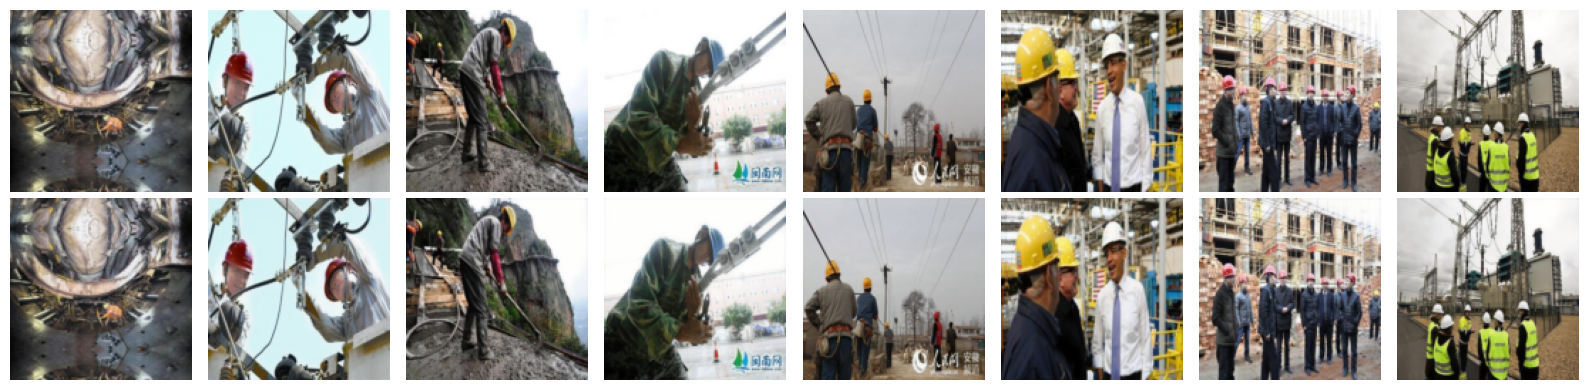

Saved model: /content/drive/MyDrive/ConstructionSiteAi/data/processed/features/ae_v2/autoencoder_v2_best.pth
Outputs: /content/drive/MyDrive/ConstructionSiteAi/data/processed/features/ae_v2


In [10]:
# ---------------- RECONSTRUCTION GRID ----------------
orig = torch.cat(originals)[:8]
rec = torch.cat(reconstructions)[:8]

fig, axes = plt.subplots(2, len(orig), figsize=(16, 4))
for i in range(len(orig)):
    axes[0, i].imshow(orig[i].permute(1, 2, 0).numpy())
    axes[1, i].imshow(rec[i].permute(1, 2, 0).numpy())
    axes[0, i].axis("off")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed")
plt.tight_layout()
plt.savefig(
    os.path.join(OUT, "ae_v2_reconstruction.png"),
    dpi=150, bbox_inches="tight"
)
plt.show()

print("Saved model:", best_path)
print("Outputs:", OUT)